# Лабораторная работа 01

## Первичный анализ

### Импорт таблиц

Для начала импортируем таблицу с помощью библиотеки `ucimlrepo`. Там обе таблицы: для красного и белого вина соответственно.

In [1]:
seed = 228
test_size = 0.2
n_folds = 5


In [2]:
import matplotlib.pyplot as plt
from ucimlrepo import fetch_ucirepo

wine_quality = fetch_ucirepo(id=186)
X = wine_quality.data.features
y = wine_quality.data.targets["quality"]
data = X.join(y)

data.head()

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


### Оценка

На сайте указано, что пустых значений в таблице нет, а в целях конфиденциальности были убраны опознавательные знаки винных компаний. Поэтому они так же могут повторяться — это нормально.

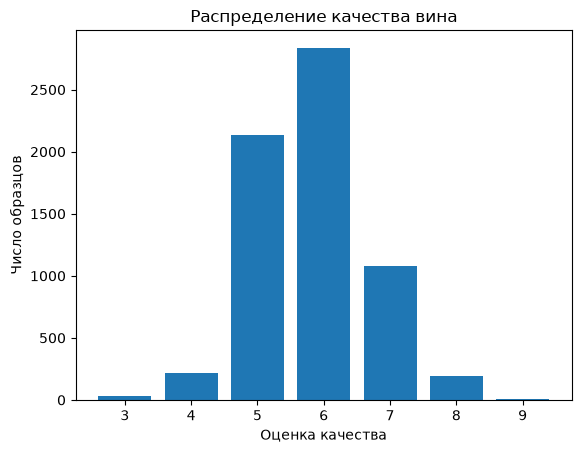

In [3]:
counts = y.value_counts().sort_index()
plt.bar(counts.index, counts.values)
plt.xlabel("Оценка качества")
plt.ylabel("Число образцов")
plt.title("Распределение качества вина")
plt.show()

Пока отсюда видно только то, что большая часть вин имеет качество в районе 5-7.

### Цвет вина и зависимости параметров от качества

В объединённом наборе сначала идут 1 599 образцов красного вина, затем образцы белого. Добавим булев признак `is_white`: `False` для красного и `True` для белого вина.


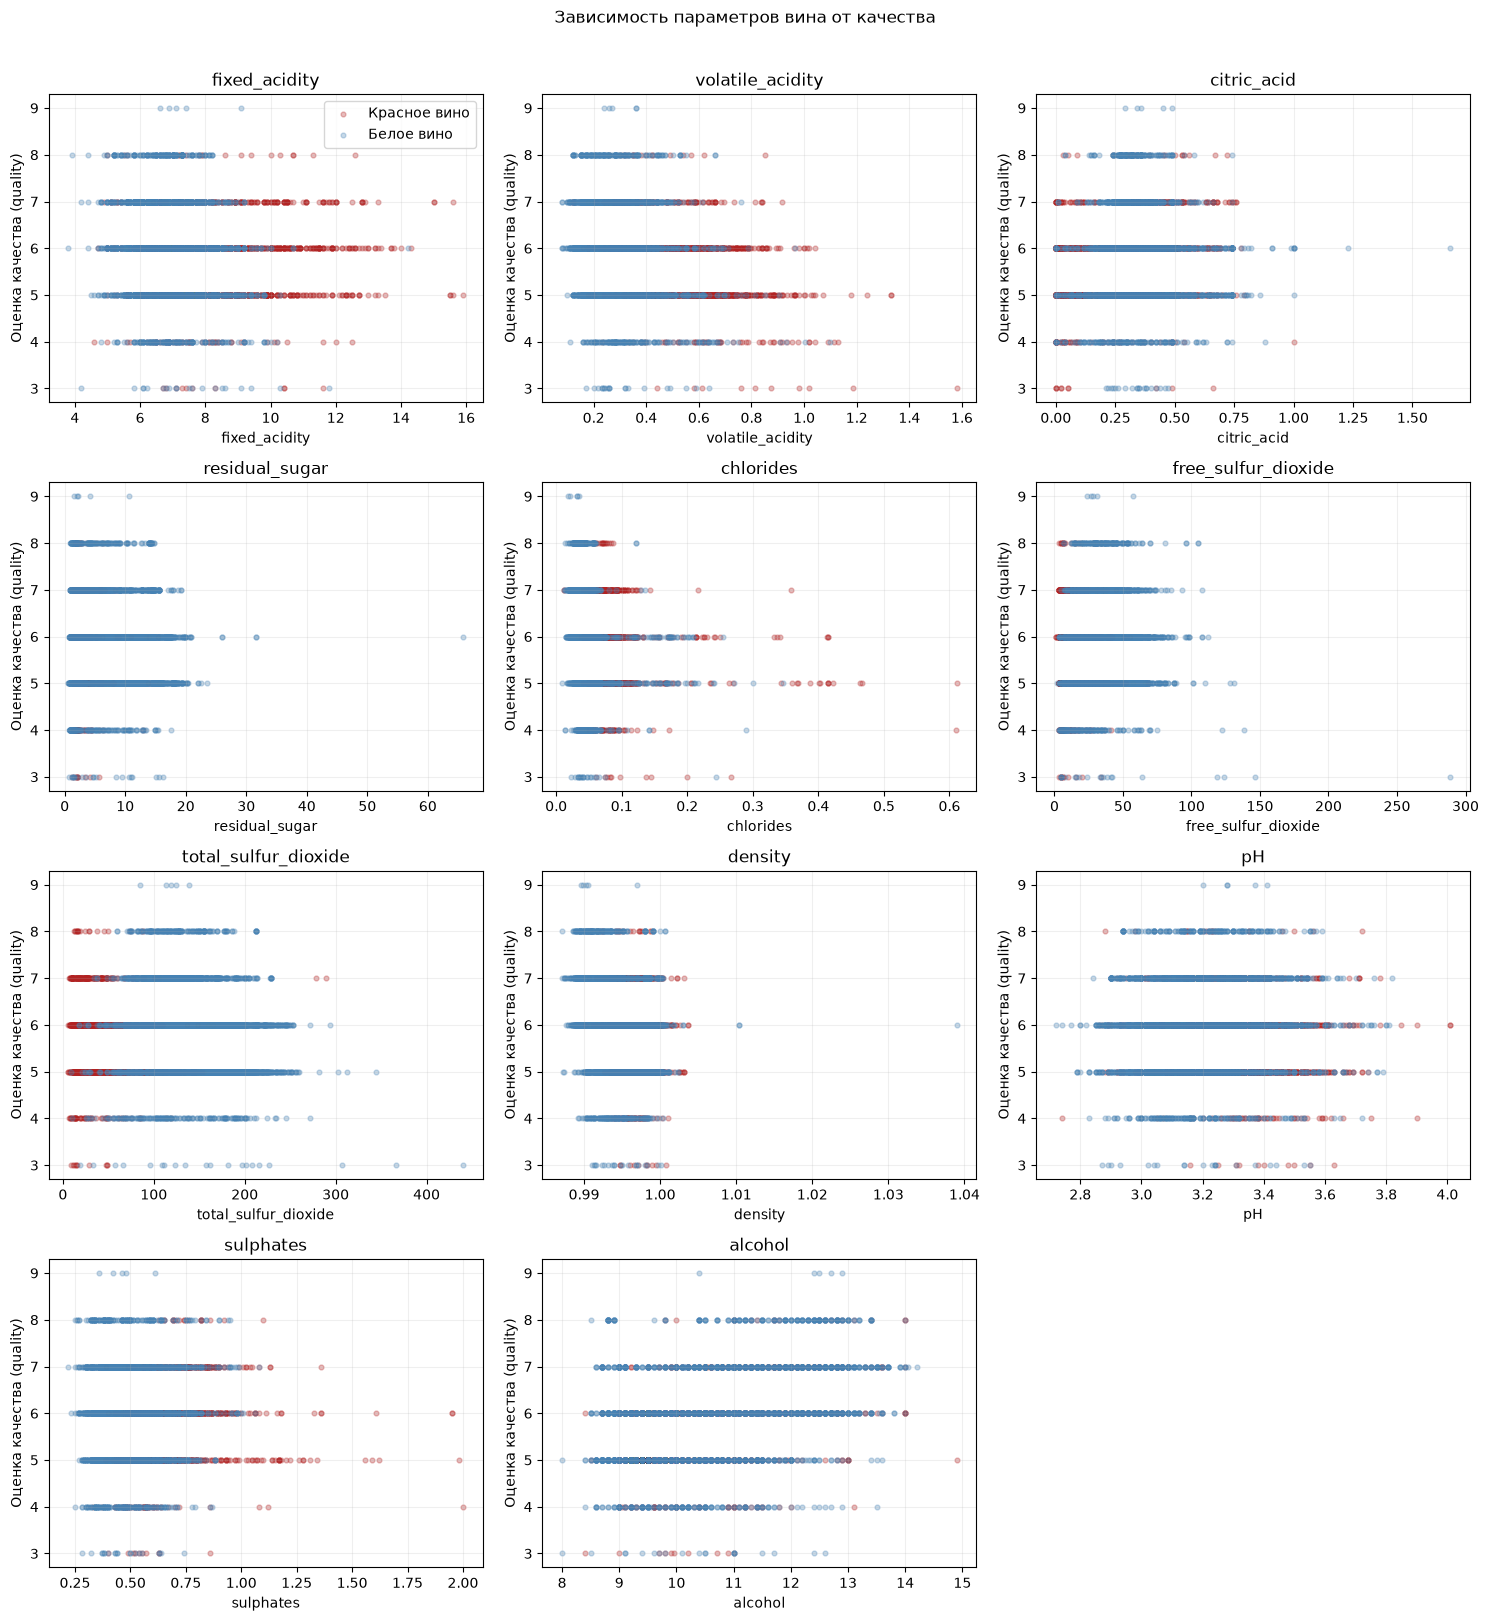

In [4]:
import math

# В исходном объединённом наборе красные вина расположены перед белыми.
red_wine_count = 1599
assert len(data) == 6497, "Проверьте состав и порядок строк набора Wine Quality"
data["is_white"] = data.index >= red_wine_count

# Для каждого параметра покажем его значения при разных оценках quality.
parameters = [column for column in data.columns if column not in ("quality", "is_white")]
ncols = 3
nrows = math.ceil(len(parameters) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows), squeeze=False)

wine_types = [(False, "Красное вино", "firebrick"), (True, "Белое вино", "steelblue")]
for parameter, ax in zip(parameters, axes.flat):
    for is_white, label, color in wine_types:
        subset = data[data["is_white"] == is_white]
        ax.scatter(subset[parameter], subset["quality"], label=label, color=color, alpha=0.3, s=12)
    ax.set_title(parameter)
    ax.set_xlabel(parameter)
    ax.set_ylabel("Оценка качества (quality)")
    ax.grid(alpha=0.2)

for ax in axes.flat[len(parameters):]:
    ax.set_visible(False)

axes.flat[0].legend()
fig.suptitle("Зависимость параметров вина от качества", y=1.01)
fig.tight_layout()
plt.show()


### Корреляция параметров с качеством

Посчитаем корреляцию Пирсона каждого параметра, включая цвет вина (`is_white`), с оценкой `quality`.


,Корреляция с quality
pH,0.019506
residual_sugar,-0.036980
sulphates,0.038485
total_sulfur_dioxide,-0.041385
free_sulfur_dioxide,0.055463
fixed_acidity,-0.076743
citric_acid,0.085532
is_white,0.119323
chlorides,-0.200666
volatile_acidity,-0.265699


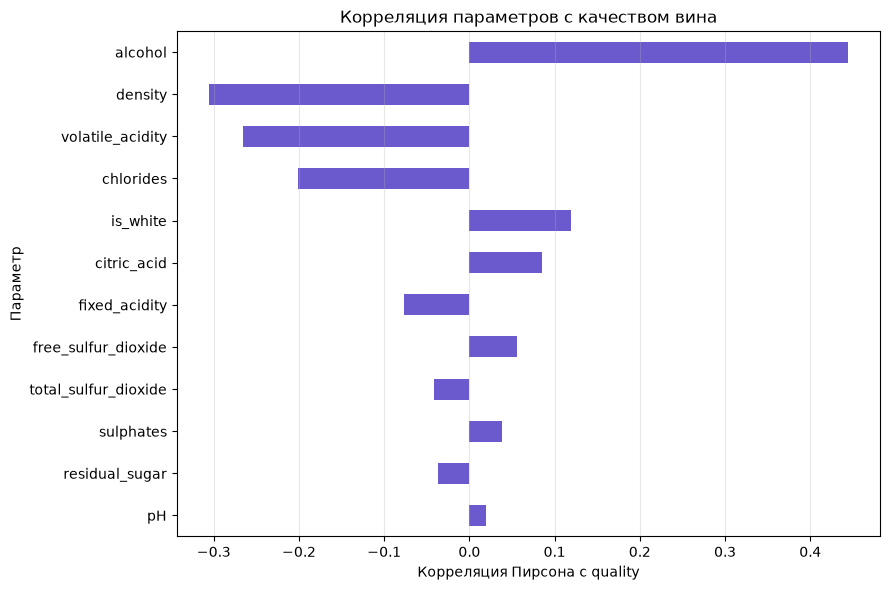

In [5]:
# Для корреляции переведём булев признак цвета в числа: False = 0, True = 1.
correlation_data = data.drop(columns="quality").copy()
correlation_data["is_white"] = correlation_data["is_white"].astype(int)

quality_correlations = correlation_data.corrwith(data["quality"]).sort_values(key=lambda values: values.abs())
display(quality_correlations.rename("Корреляция с quality").to_frame())

quality_correlations.sort_values(key=lambda values: values.abs()).plot(kind="barh", figsize=(9, 6), color="slateblue")
plt.xlabel("Корреляция Пирсона с quality")
plt.ylabel("Параметр")
plt.title("Корреляция параметров с качеством вина")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


Из значимых здесь можно выделить только параметры `alcohol` и `density`.

### Форма зависимостей на обучающей выборке

Для каждого числового признака точки показывают медиану признака и среднее качество в десяти квантильных интервалах. Попробуем сразу наделать полиномов, чтобы посмотреть как функция себя ведет.


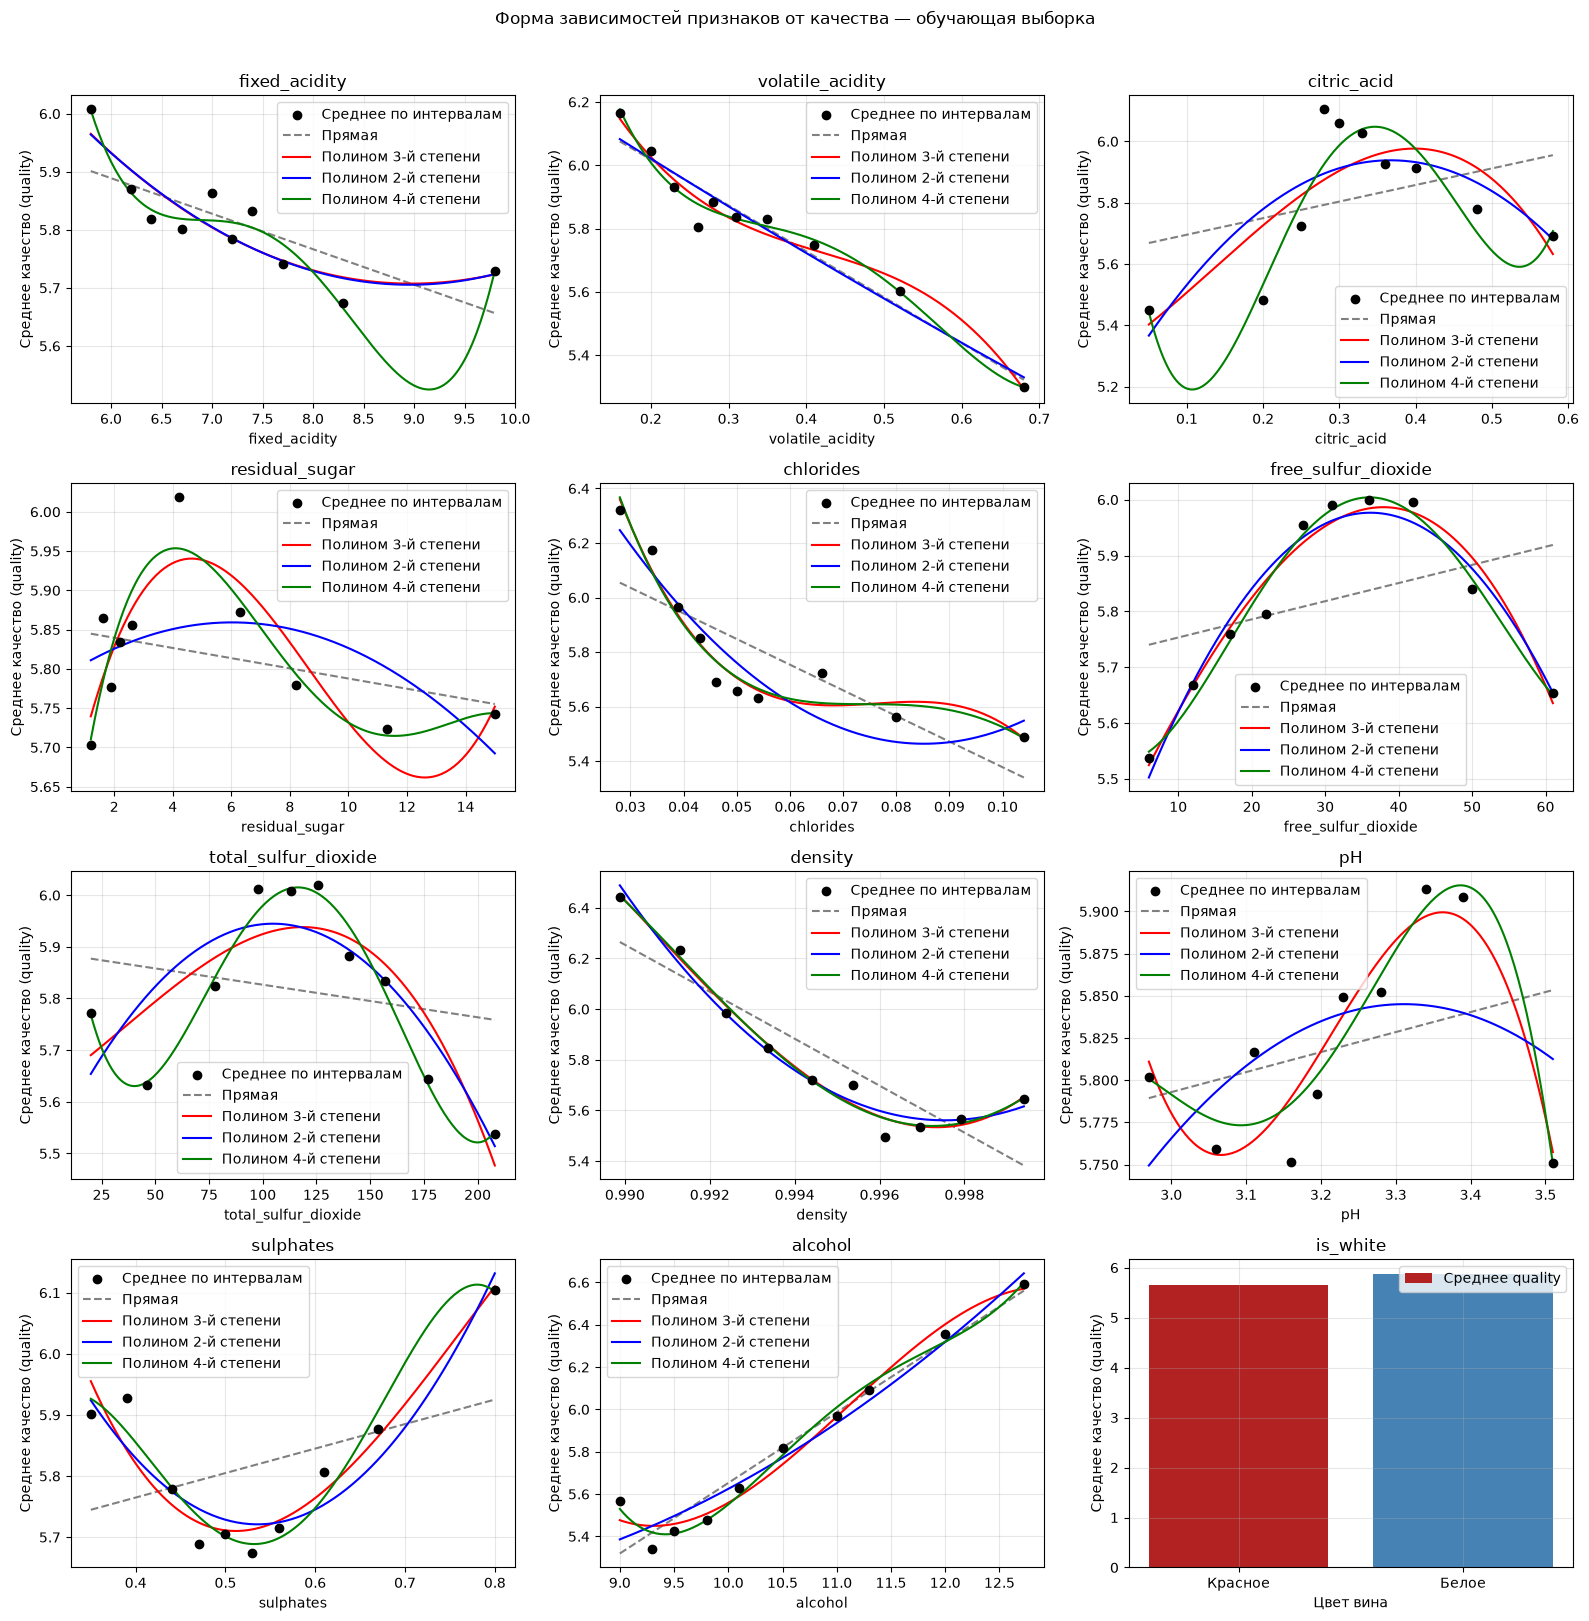

In [6]:
import numpy as np
import pandas as pd
from numpy.polynomial import Polynomial
from sklearn.model_selection import train_test_split

train_data, _ = train_test_split(data, test_size=test_size, random_state=seed, stratify=data["quality"])
numeric_features = [column for column in train_data.select_dtypes(include="number").columns if column != "quality"]
features_to_plot = [*numeric_features, "is_white"]
ncols = 3
nrows = math.ceil(len(features_to_plot) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows), squeeze=False)

for feature, ax in zip(features_to_plot, axes.flat):
    if feature == "is_white":
        mean_quality = train_data.groupby("is_white")["quality"].mean().reindex([False, True])
        ax.bar(["Красное", "Белое"], mean_quality, color=["firebrick", "steelblue"], label="Среднее quality")
        ax.set_xlabel("Цвет вина")
    else:
        bins = pd.qcut(train_data[feature], q=10, duplicates="drop")
        points = train_data.assign(bin=bins).groupby("bin", observed=True).agg(x=(feature, "median"), y=("quality", "mean"))
        x, y = points["x"].to_numpy(), points["y"].to_numpy()
        ax.scatter(x, y, color="black", label="Среднее по интервалам", zorder=3)
        x_line = np.linspace(x.min(), x.max(), 200)
        ax.plot(x_line, Polynomial.fit(x, y, 1)(x_line), color="gray", linestyle="--", label="Прямая")
        ax.plot(x_line, Polynomial.fit(x, y, 3)(x_line), color="red", label="Полином 3-й степени")
        ax.plot(x_line, Polynomial.fit(x, y, 2)(x_line), color="blue", label="Полином 2-й степени")
        ax.plot(x_line, Polynomial.fit(x, y, 4)(x_line), color="green", label="Полином 4-й степени")
        ax.set_xlabel(feature)

    ax.set_title(feature)
    ax.set_ylabel("Среднее качество (quality)")
    ax.legend()
    ax.grid(alpha=0.3)

for ax in axes.flat[len(features_to_plot):]:
    ax.set_visible(False)

fig.suptitle("Форма зависимостей признаков от качества — обучающая выборка", y=1.01)
fig.tight_layout()
plt.show()


Ну, очевидно, что одной прямой на каждый признак не хватает. Нужны полиномы. Мне по графику ближе всех кажется 3-й полином, его и будем пробовать.

## Baseline

### Baseline: предсказание среднего качества

Отделим 20% данных для теста. Cross-validation и метрики на обучающей выборке считаются только на оставшихся 80%, тестовые метрики считаются один раз после обучения baseline на всей обучающей выборке.


In [7]:
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_validate, train_test_split

X_baseline = data.drop(columns="quality")
y_baseline = data["quality"]
X_train_baseline, X_test_baseline, y_train_baseline, y_test_baseline = train_test_split(
    X_baseline, y_baseline, test_size=test_size, random_state=seed, stratify=y_baseline
)
cv = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
baseline_scores = cross_validate(
    DummyRegressor(strategy="mean"), X_train_baseline, y_train_baseline,
    cv=cv, scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
)
baseline_model = DummyRegressor(strategy="mean").fit(X_train_baseline, y_train_baseline)
train_predictions = baseline_model.predict(X_train_baseline)
test_predictions = baseline_model.predict(X_test_baseline)
baseline_results = pd.DataFrame([{
    "MAE-CV-Train": -baseline_scores["test_MAE"].mean(),
    "RMSE-CV-Train": -baseline_scores["test_RMSE"].mean(),
    "MAE-Train": mean_absolute_error(y_train_baseline, train_predictions),
    "RMSE-Train": np.sqrt(np.mean((y_train_baseline - train_predictions) ** 2)),
    "MAE-Test": mean_absolute_error(y_test_baseline, test_predictions),
    "RMSE-Test": np.sqrt(np.mean((y_test_baseline - test_predictions) ** 2)),
}], index=["Baseline"])
display(baseline_results.round(3))


,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Baseline,0.686,0.873,0.685,0.873,0.686,0.874


Здорово, теперь давайте попробуем обычную линейную регрессию.

## Линейная регрессия

Оценим линейную регрессию 5-fold cross-validation на обучающих 80% данных, затем один раз посчитаем метрики на отложенной тестовой выборке.


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_validate, train_test_split

X = data.drop(columns="quality")
y = data["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=seed, stratify=y
)
cv = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
linear_scores = cross_validate(
    LinearRegression(), X_train, y_train, cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
)
linear_model = LinearRegression().fit(X_train, y_train)
train_predictions = linear_model.predict(X_train)
test_predictions = linear_model.predict(X_test)
linear_results = pd.DataFrame([{
    "MAE-CV-Train": -linear_scores["test_MAE"].mean(),
    "RMSE-CV-Train": -linear_scores["test_RMSE"].mean(),
    "MAE-Train": mean_absolute_error(y_train, train_predictions),
    "RMSE-Train": np.sqrt(np.mean((y_train - train_predictions) ** 2)),
    "MAE-Test": mean_absolute_error(y_test, test_predictions),
    "RMSE-Test": np.sqrt(np.mean((y_test - test_predictions) ** 2)),
}], index=["Линейная регрессия"])
display(linear_results.round(3))


,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Линейная регрессия,0.573,0.739,0.571,0.736,0.561,0.718


Все очень плохо, baseline улучшается, но RMSE > 0.7. Попробуем добавить полиномы, основываясь на предыдущие рассуждения.

### Полиномиальная регрессия 3-й степени

Добавим полиномиальные признаки третьей степени и выведем метрики в том же формате.


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

X = data.drop(columns="quality")
y = data["quality"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=test_size, random_state=seed, stratify=y
)
cv = KFold(n_splits=n_folds, shuffle=True, random_state=seed)
polynomial_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)
polynomial_scores = cross_validate(
    polynomial_model, X_train, y_train, cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
)
polynomial_model.fit(X_train, y_train)
train_predictions = polynomial_model.predict(X_train)
test_predictions = polynomial_model.predict(X_test)
polynomial_results = pd.DataFrame([{
    "MAE-CV-Train": -polynomial_scores["test_MAE"].mean(),
    "RMSE-CV-Train": -polynomial_scores["test_RMSE"].mean(),
    "MAE-Train": mean_absolute_error(y_train, train_predictions),
    "RMSE-Train": np.sqrt(np.mean((y_train - train_predictions) ** 2)),
    "MAE-Test": mean_absolute_error(y_test, test_predictions),
    "RMSE-Test": np.sqrt(np.mean((y_test - test_predictions) ** 2)),
}], index=["Полиномиальная регрессия 3-й степени"])
display(polynomial_results.round(3))


,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Полиномиальная регрессия 3-й степени,0.567,0.931,0.539,0.688,0.547,0.703


RMSE-Test снизился до 0.7033, но CV-Train вырос до 0.9307.
На train ошибка заметно меньше, чем на проверочных частях. Это повод предположить переобучение
или неустойчивость полиномиальной модели. Среди полиномов 3-й степени много связанных и повторяющихся
членов (454 столбца). Попробуем ограничить коэффициенты с помощью Lasso. Перед этим нужно масштабирование.

### Масштабирование и регуляризация Lasso

После полиномов третьей степени применим `StandardScaler`, затем Lasso с `alpha=0.0015`.
Это значение выбрано в предыдущем подборе по CV RMSE.
Масштабирование обучается внутри каждого фолда благодаря Pipeline.
Оцениваем модель на прежних пяти фолдах, затем обучаем её на всей обучающей выборке.


In [10]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

lasso_model = make_pipeline(
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Lasso(alpha=0.0015, max_iter=100000, tol=0.0001,
          selection="random", random_state=seed)
)
lasso_scores = cross_validate(
    lasso_model, X_train, y_train, cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
)
lasso_model.fit(X_train, y_train)
train_predictions = lasso_model.predict(X_train)
test_predictions = lasso_model.predict(X_test)
lasso_results = pd.DataFrame([{
    "MAE-CV-Train": -lasso_scores["test_MAE"].mean(),
    "RMSE-CV-Train": -lasso_scores["test_RMSE"].mean(),
    "MAE-Train": mean_absolute_error(y_train, train_predictions),
    "RMSE-Train": np.sqrt(np.mean((y_train - train_predictions) ** 2)),
    "MAE-Test": mean_absolute_error(y_test, test_predictions),
    "RMSE-Test": np.sqrt(np.mean((y_test - test_predictions) ** 2)),
}], index=["Полиномы + StandardScaler + Lasso"])
display(lasso_results.round(4))


,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Полиномы + StandardScaler + Lasso,0.5544,0.753,0.5389,0.6923,0.541,0.6943


In [11]:
display(pd.concat([
    baseline_results, linear_results, polynomial_results, lasso_results
]).round(3))


,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Baseline,0.686,0.873,0.685,0.873,0.686,0.874
Линейная регрессия,0.573,0.739,0.571,0.736,0.561,0.718
Полиномиальная регрессия 3-й степени,0.567,0.931,0.539,0.688,0.547,0.703
Полиномы + StandardScaler + Lasso,0.554,0.753,0.539,0.692,0.541,0.694


Используем `alpha=0.0015`, найденное в предыдущем подборе по CV на обучающих данных.
После добавления стратификации метрики пересчитаны без повторного подбора параметра:
CV RMSE = 0.75296, Train RMSE = 0.69232, Test RMSE = 0.69429.

### Йео-Джонсон

Если посмотреть на первый график можно увидеть всякие странные хвосты по значениям, которые уходят куда-то от основной массы вин. Вот эти редкие скачки тоже могут плохо менять. Можем попробовать еще до всех манипуляций применить трансформацию Йео-Джонсона, чтобы сделать графики более равномерным.

Проверим полный Pipeline: **Yeo–Johnson → полиномы степени 3 → StandardScaler → Lasso**.
Преобразуем только 11 числовых характеристик, сохраняя цвет бинарным.
Используем найденное ранее `alpha=0.005` и те же пять фолдов для оценки.
Все обучаемые преобразования находятся внутри Pipeline.


In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer

numeric_columns = X_train.columns.drop("is_white").tolist()
yeo_transform = ColumnTransformer([
    ("numeric", PowerTransformer(method="yeo-johnson"), numeric_columns)
], remainder="passthrough")
yeo_lasso_model = make_pipeline(
    yeo_transform,
    PolynomialFeatures(degree=3, include_bias=False),
    StandardScaler(),
    Lasso(alpha=0.005, max_iter=100000, tol=0.0001,
          selection="random", random_state=seed)
)
yeo_lasso_scores = cross_validate(
    yeo_lasso_model, X_train, y_train, cv=cv,
    scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
)
yeo_lasso_model.fit(X_train, y_train)
train_predictions = yeo_lasso_model.predict(X_train)
test_predictions = yeo_lasso_model.predict(X_test)
yeo_lasso_results = pd.DataFrame([{
    "MAE-CV-Train": -yeo_lasso_scores["test_MAE"].mean(),
    "RMSE-CV-Train": -yeo_lasso_scores["test_RMSE"].mean(),
    "MAE-Train": mean_absolute_error(y_train, train_predictions),
    "RMSE-Train": np.sqrt(np.mean((y_train - train_predictions) ** 2)),
    "MAE-Test": mean_absolute_error(y_test, test_predictions),
    "RMSE-Test": np.sqrt(np.mean((y_test - test_predictions) ** 2)),
}], index=["Yeo–Johnson + Полиномы + StandardScaler + Lasso"])


In [13]:
display(pd.concat([
    baseline_results, linear_results, polynomial_results, lasso_results, yeo_lasso_results
]).round(4))


,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Baseline,0.6858,0.8733,0.6855,0.8730,0.6861,0.8738
Линейная регрессия,0.5731,0.7390,0.5709,0.7363,0.5611,0.7179
Полиномиальная регрессия 3-й степени,0.5670,0.9307,0.5394,0.6881,0.5472,0.7033
Полиномы + StandardScaler + Lasso,0.5544,0.7530,0.5389,0.6923,0.5410,0.6943
Yeo–Johnson + Полиномы + StandardScaler + Lasso,0.5389,0.6933,0.5192,0.6658,0.5431,0.6915


## Что получилось с данными и линейной моделью

Йео-Джонсон вместе с полиномами и Lasso дал CV RMSE около 0.693. Уже лучше исходной линейной регрессии,
но пока непонятно, хватит ли линейной модели даже с такими преобразованиями. Дальше попробуем деревья.

Перед этим коротко проверим состав таблицы. Повторы сохраняем: одинаковые измеренные характеристики
не означают, что это одно и то же вино. По одним данным также нельзя установить причину каждого повтора.

In [14]:
print("Строк и столбцов:", data.shape)
print("Пропусков:", data.isna().sum().sum())
print("Полных повторов:", data.duplicated().sum())
display(data.describe().round(3))

Строк и столбцов: (6497, 13)
Пропусков: 0
Полных повторов: 1177


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
count,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000,6497.000
mean,7.215,0.340,0.319,5.443,0.056,30.525,115.745,0.995,3.219,0.531,10.492,5.818
std,1.296,0.165,0.145,4.758,0.035,17.749,56.522,0.003,0.161,0.149,1.193,0.873
min,3.800,0.080,0.000,0.600,0.009,1.000,6.000,0.987,2.720,0.220,8.000,3.000
25%,6.400,0.230,0.250,1.800,0.038,17.000,77.000,0.992,3.110,0.430,9.500,5.000
50%,7.000,0.290,0.310,3.000,0.047,29.000,118.000,0.995,3.210,0.510,10.300,6.000
75%,7.700,0.400,0.390,8.100,0.065,41.000,156.000,0.997,3.320,0.600,11.300,6.000
max,15.900,1.580,1.660,65.800,0.611,289.000,440.000,1.039,4.010,2.000,14.900,9.000


В таблице 6497 вин, 11 числовых характеристик, цвет и целевая переменная `quality`.
Пропусков нет. Большинство оценок сосредоточено около 5-7, поэтому крайние оценки будут сложнее для обучения.
Положительная корреляция алкоголя с качеством означает, что в этом наборе более крепкие вина в среднем
оценены выше. У плотности, летучей кислотности и хлоридов связь отрицательная.
Это основания учитывать признаки в модели. Слабая отдельная корреляция не повод сразу удалять признак:
его связь с качеством может быть нелинейной или зависеть от других характеристик.

Для новых моделей сделаем одну короткую функцию, чтобы не повторять одинаковый подсчет метрик.

In [15]:
def evaluate_model(model):
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring={"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error"}
    )
    model.fit(X_train, y_train)
    train_prediction = model.predict(X_train)
    test_prediction = model.predict(X_test)
    return {
        "MAE-CV-Train": -scores["test_MAE"].mean(),
        "RMSE-CV-Train": -scores["test_RMSE"].mean(),
        "MAE-Train": mean_absolute_error(y_train, train_prediction),
        "RMSE-Train": np.sqrt(np.mean((y_train - train_prediction) ** 2)),
        "MAE-Test": mean_absolute_error(y_test, test_prediction),
        "RMSE-Test": np.sqrt(np.mean((y_test - test_prediction) ** 2)),
    }

## Random Forest

В линейной модели пришлось самим добавлять изгибы и взаимодействия. Деревья умеют находить такие
зависимости через разбиения данных. Случайный лес усредняет прогнозы многих деревьев и за счет этого
снижает разброс предсказаний. Возьмем 100 деревьев, полиномы и масштабирование здесь не добавляем.

In [16]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(n_estimators=100, random_state=seed, n_jobs=-1)
forest_results = pd.DataFrame([evaluate_model(forest_model)], index=["Random Forest"])
display(forest_results.round(4))

,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Random Forest,0.4552,0.6303,0.162,0.2286,0.4252,0.5905


У леса CV RMSE получился 0.6303, Test RMSE - 0.5905, Test MAE - 0.4252.
Это лучше baseline и всех рассмотренных линейных вариантов. Похоже, разбиения деревьев лучше
описывают совместные нелинейные зависимости признаков. Train RMSE всего 0.2286: разрыв с CV остался,
поэтому ориентироваться только на обучающую ошибку здесь было бы неправильно.

## Gradient Boosting

Теперь попробуем строить деревья последовательно: каждое следующее будет исправлять оставшиеся ошибки.
Это градиентный бустинг. Возьмем проверенные раньше настройки: 300 деревьев, глубину 5 и скорость
обучения 0.1. Оставляем те же признаки, train/test и пять фолдов.

In [17]:
from sklearn.ensemble import GradientBoostingRegressor

boosting_model = GradientBoostingRegressor(
    n_estimators=300, max_depth=5, learning_rate=0.1, random_state=seed
)
boosting_results = pd.DataFrame([evaluate_model(boosting_model)], index=["Gradient Boosting"])
display(boosting_results.round(4))

,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Gradient Boosting,0.4862,0.6562,0.2857,0.3773,0.4618,0.6155


У бустинга CV RMSE равен 0.6562, Test RMSE - 0.6155, Test MAE - 0.4618.
Он тоже обошел линейные варианты, но лес на этих настройках оказался лучше.
Одна из возможных причин - разная гибкость моделей: лес усредняет деревья без заданного ограничения
глубины, а у бустинга глубина ограничена пятью. При выбранной скорости обучения и числе деревьев
его Train RMSE также выше: 0.3773 против 0.2286. Это сравнение конкретных конфигураций,
а не доказательство, что лес всегда лучше бустинга.

## Какие признаки использует линейная регрессия

Сырые коэффициенты исходной линейной регрессии сравнивать неудобно: у плотности и алкоголя разные
единицы и диапазоны. Умножим каждый коэффициент на стандартное отклонение признака в train.
Получим изменение прогноза при увеличении признака на одно стандартное отклонение, если остальные
признаки фиксированы. Это также коэффициенты эквивалентной регрессии на стандартизованных признаках.
Знак показывает направление связи внутри модели.

,Коэффициент,На одно std
density,-103.5393,-0.3126
residual_sugar,0.0631,0.3010
alcohol,0.2214,0.2657
volatile_acidity,-1.4731,-0.2418
is_white,-0.3602,-0.1548
fixed_acidity,0.0963,0.1247
sulphates,0.6743,0.1022
pH,0.5239,0.0843
free_sulfur_dioxide,0.0042,0.0757
total_sulfur_dioxide,-0.0013,-0.0714


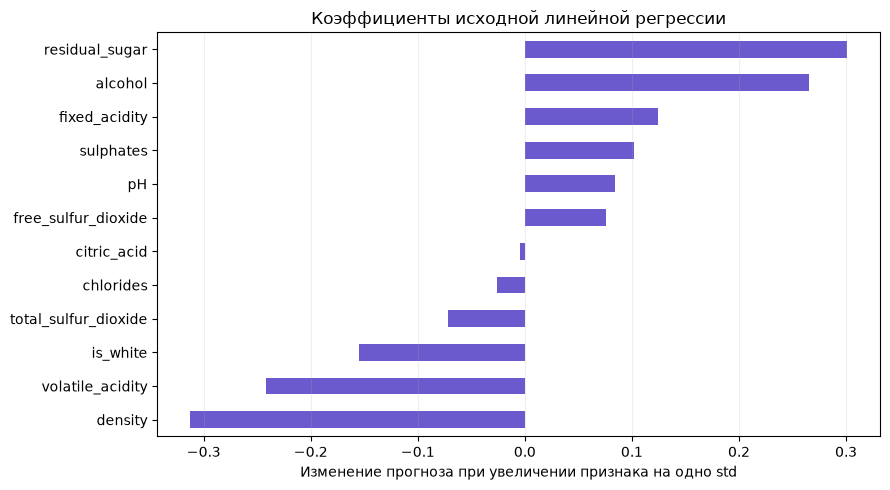

In [18]:
coefficients = pd.DataFrame({
    "Коэффициент": linear_model.coef_,
    "На одно std": linear_model.coef_ * X_train.std(ddof=0),
}, index=X_train.columns).sort_values("На одно std", key=abs, ascending=False)
display(coefficients.round(4))
coefficients["На одно std"].sort_values().plot.barh(figsize=(9, 5), color="slateblue")
plt.xlabel("Изменение прогноза при увеличении признака на одно std")
plt.title("Коэффициенты исходной линейной регрессии")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

По модулю коэффициентов на одно std выделяются плотность (-0.313), сахар (+0.301),
алкоголь (+0.266) и летучая кислотность (-0.242). Сырые -103.5 у плотности сами по себе не означают
огромную важность: после учета масштаба она сопоставима с сахаром и алкоголем.

Интересно, что у сахара почти нет отдельной корреляции с quality, но его коэффициент в совместной
модели заметный. Общая корреляция и коэффициент при фиксированных остальных признаках отвечают
на разные вопросы. Плотность, сахар и алкоголь связаны между собой, поэтому такие коэффициенты
могут быть чувствительны к составу признаков. Это не повод объявлять сахар причиной высокого качества.

В лучшем линейном пайплайне коэффициенты относятся уже к полиномам преобразованных признаков.
Посмотрим на 15 самых крупных по модулю. Это позволяет понять, какие члены оставил Lasso,
но считать их непосредственной важностью исходных характеристик нельзя.

Ненулевых коэффициентов: 144 из 454


,Коэффициент
chlorides density^2,-0.0441
chlorides total_sulfur_dioxide alcohol,-0.0447
volatile_acidity residual_sugar^2,-0.0462
density alcohol,-0.0522
volatile_acidity^2 residual_sugar,0.0544
chlorides density pH,0.0551
chlorides density,0.0563
alcohol is_white^2,0.0600
total_sulfur_dioxide density sulphates,0.0759
free_sulfur_dioxide^2 is_white,-0.0806


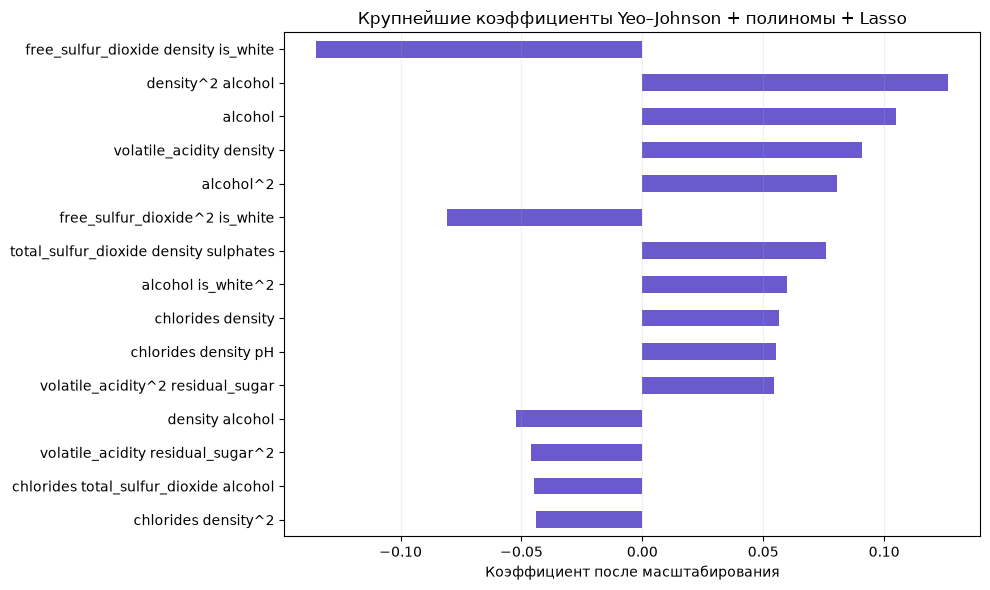

In [19]:
feature_names = yeo_lasso_model[:-1].get_feature_names_out()
feature_names = [name.replace("numeric__", "").replace("remainder__", "") for name in feature_names]
lasso_coefficients = pd.Series(yeo_lasso_model[-1].coef_, index=feature_names)
print("Ненулевых коэффициентов:", (lasso_coefficients != 0).sum(), "из", len(lasso_coefficients))
top_lasso = lasso_coefficients.sort_values(key=abs).tail(15)
display(top_lasso.rename("Коэффициент").to_frame().round(4))
top_lasso.plot.barh(figsize=(10, 6), color="slateblue")
plt.xlabel("Коэффициент после масштабирования")
plt.title("Крупнейшие коэффициенты Yeo–Johnson + полиномы + Lasso")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

Lasso оставил 144 ненулевых коэффициента из 454. Среди крупнейших по модулю есть
`free_sulfur_dioxide density is_white`, `density^2 alcohol` и `alcohol`.
Значит, модель использует и прямую связь, и дополнительные зависимости.
При этом `is_white^2` совпадает с `is_white`, поэтому часть полиномиальных столбцов повторяется.
Коэффициент одного такого члена не является самостоятельной важностью признака:
связанные и одинаковые члены нужно учитывать вместе.

## Важность признаков у деревьев

У леса и бустинга есть `feature_importances_`. Эти значения отражают, насколько признаки помогали
уменьшать ошибку в разбиениях деревьев на обучении. Внутри каждого такого рейтинга сумма равна единице.
Получим таблицу и сравним модели на одном графике.

,Random Forest,Gradient Boosting
alcohol,0.2460,0.2811
volatile_acidity,0.1226,0.1251
free_sulfur_dioxide,0.0931,0.0898
sulphates,0.0774,0.0658
residual_sugar,0.0761,0.0853
total_sulfur_dioxide,0.0737,0.0686
chlorides,0.0682,0.0643
pH,0.0657,0.0559
citric_acid,0.0599,0.0558
density,0.0593,0.0608


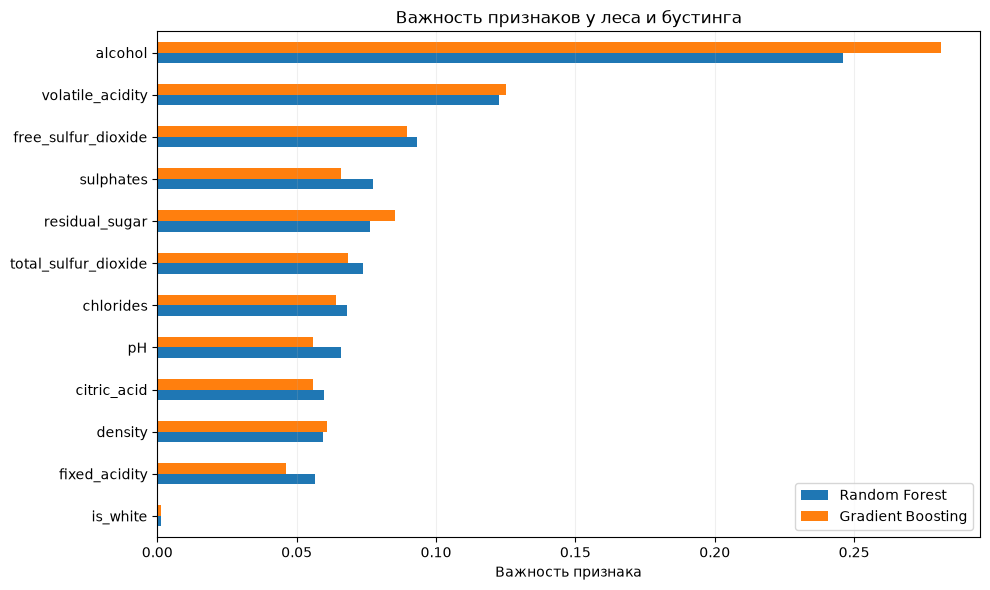

In [20]:
tree_importance = pd.DataFrame({
    "Random Forest": forest_model.feature_importances_,
    "Gradient Boosting": boosting_model.feature_importances_,
}, index=X_train.columns).sort_values("Random Forest", ascending=False)
display(tree_importance.round(4))
tree_importance.iloc[::-1].plot.barh(figsize=(10, 6))
plt.xlabel("Важность признака")
plt.title("Важность признаков у леса и бустинга")
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

У обоих алгоритмов первые три признака совпали: `alcohol`, `volatile_acidity`,
`free_sulfur_dioxide`. Важность алкоголя составляет примерно 0.246 у леса и 0.281 у бустинга.
Это согласуется с первичным анализом: у алкоголя самая заметная положительная корреляция с quality,
а у летучей кислотности связь отрицательная. Сами важности деревьев знака связи не показывают.

При этом плотность у деревьев не на первом месте, хотя ее отдельная корреляция и коэффициент
линейной модели заметны. Возможно, часть той же информации деревья получают через алкоголь и сахар.
У свободного диоксида серы отдельная линейная корреляция слабая, но его высокая важность согласуется
с изгибом на графике зависимости качества. Цвет имеет очень маленькую важность в деревьях.
Связанные признаки могут делить важность между собой в общем-то :D

## Итоговое сравнение

Соберем все варианты вместе. У них одинаковые train/test, а CV считается на тех же пяти фолдах.
Лучшую модель выбираем по минимальному `RMSE-CV-Train`. Тестовые RMSE и MAE показываем как итоговую
оценку на отложенных данных.

In [21]:
all_results = pd.concat([
    baseline_results, linear_results, polynomial_results, lasso_results,
    yeo_lasso_results, forest_results, boosting_results
])
models = dict(zip(all_results.index, [
    baseline_model, linear_model, polynomial_model, lasso_model,
    yeo_lasso_model, forest_model, boosting_model
]))
best_name = all_results["RMSE-CV-Train"].idxmin()
best_model = models[best_name]
display(all_results.sort_values("RMSE-CV-Train").round(4))
print("Лучшая модель по CV RMSE:", best_name)

Лучшая модель по CV RMSE: Random Forest


,MAE-CV-Train,RMSE-CV-Train,MAE-Train,RMSE-Train,MAE-Test,RMSE-Test
Random Forest,0.4552,0.6303,0.1620,0.2286,0.4252,0.5905
Gradient Boosting,0.4862,0.6562,0.2857,0.3773,0.4618,0.6155
Yeo–Johnson + Полиномы + StandardScaler + Lasso,0.5389,0.6933,0.5192,0.6658,0.5431,0.6915
Линейная регрессия,0.5731,0.7390,0.5709,0.7363,0.5611,0.7179
Полиномы + StandardScaler + Lasso,0.5544,0.7530,0.5389,0.6923,0.5410,0.6943
Baseline,0.6858,0.8733,0.6855,0.8730,0.6861,0.8738
Полиномиальная регрессия 3-й степени,0.5670,0.9307,0.5394,0.6881,0.5472,0.7033


In [22]:
polynomial_errors = pd.DataFrame({
    "quality": y_test, "prediction": polynomial_model.predict(X_test)
})
polynomial_errors["abs_error"] = (polynomial_errors["prediction"] - polynomial_errors["quality"]).abs()
worst_poly = polynomial_errors.nlargest(1, "abs_error")
display(X_test.loc[worst_poly.index, [
    "free_sulfur_dioxide", "total_sulfur_dioxide"
]].join(worst_poly).round(3))


,free_sulfur_dioxide,total_sulfur_dioxide,quality,prediction,abs_error
652,22.0,71.0,5,8.79,3.79


По CV победил Random Forest. На test у него RMSE 0.5905 и MAE 0.4252.
Следом идет Gradient Boosting с RMSE 0.6155. Лучший линейный вариант по CV - полный
пайплайн с Йео-Джонсоном: CV RMSE 0.6933, Test RMSE 0.6915.
На нашей отложенной выборке эти три модели и полиномы с Lasso без Йео-Джонсона прошли порог 0.70.
Качество на отдельной скрытой выборке из задания этим еще не измерено.

По тестовому RMSE все обученные модели обошли baseline. По CV полиномы без регуляризации
стали исключением: их CV RMSE 0.9307 хуже baseline 0.8733, хотя Test RMSE 0.7033 заметно ниже.
Это показывает, насколько результат зависит от разбиения. На вине 652 с quality 5 полиномы
предсказали примерно 8.79. Его fixed_acidity 15.9 и alcohol 14.9 находятся у края наблюдаемого диапазона.
Это пример крупной ошибки, но один объект не объясняет все промахи модели.
Поэтому выбирать модель по одному удачному результату на test было бы неправильно.

## Где лучшая модель ошибается

Одной средней ошибки мало: посмотрим, на каких винах прогноз получается хуже.
Ошибкой будем считать `предсказание - настоящее качество`. Положительная ошибка означает завышение,
отрицательная - занижение. На втором графике хороший прогноз должен лежать около диагонали.

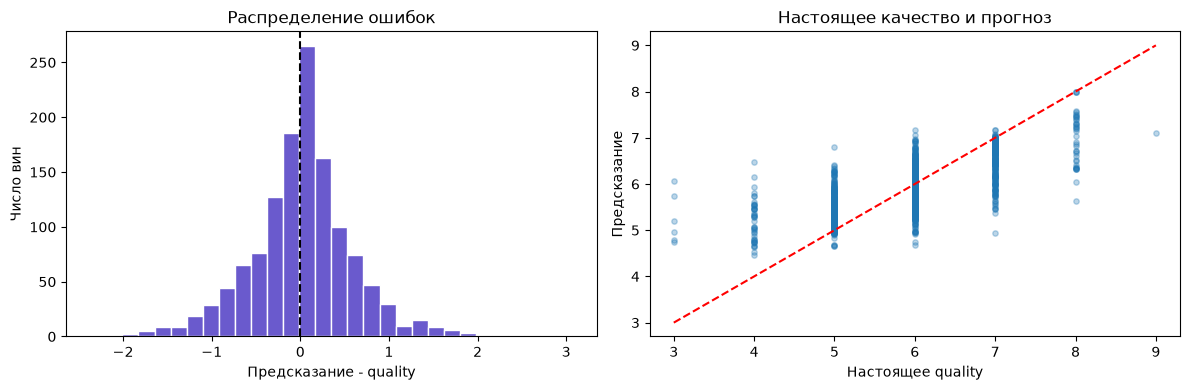

In [23]:
prediction = best_model.predict(X_test)
errors = pd.DataFrame({"quality": y_test, "prediction": prediction})
errors["error"] = errors["prediction"] - errors["quality"]
errors["abs_error"] = errors["error"].abs()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(errors["error"], bins=30, color="slateblue", edgecolor="white")
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set(title="Распределение ошибок", xlabel="Предсказание - quality", ylabel="Число вин")
axes[1].scatter(y_test, prediction, alpha=0.3, s=15)
axes[1].plot([3, 9], [3, 9], "r--")
axes[1].set(title="Настоящее качество и прогноз", xlabel="Настоящее quality", ylabel="Предсказание")
plt.tight_layout()
plt.show()

Большая часть ошибок находится около нуля; средняя ошибка примерно +0.0213.
Но маленькое среднее не означает, что модель точная на каждом вине: завышения и занижения могут
компенсироваться. Есть ошибки от -2.37 до +3.07 балла.
На графике прогнозов видно, что низкие оценки часто завышаются, а высокие занижаются.
Модель тянет крайние случаи к более распространенным значениям качества.

### Ошибки для разных оценок

Разобьем тестовые ошибки по настоящему `quality`. Рядом укажем, сколько примеров с такой оценкой было
в train: это поможет понять, где модели не хватало данных.

,train_count,count,MAE,RMSE,mean_prediction
quality,,,,,
3,24,6,2.248,2.302,5.248
4,173,43,1.217,1.298,5.217
5,1710,428,0.375,0.496,5.365
6,2269,567,0.303,0.399,5.928
7,863,216,0.525,0.673,6.480
8,154,39,1.008,1.155,6.992
9,4,1,1.900,1.900,7.100


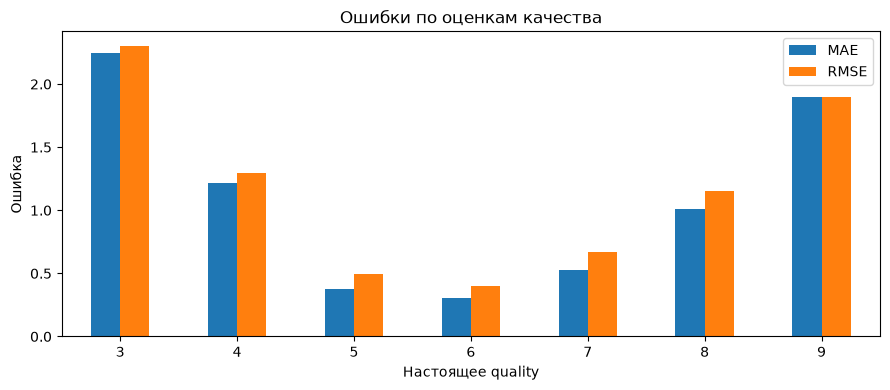

In [24]:
quality_errors = errors.groupby("quality").agg(
    count=("error", "size"),
    MAE=("abs_error", "mean"),
    RMSE=("error", lambda values: np.sqrt((values ** 2).mean())),
    mean_prediction=("prediction", "mean")
)
quality_errors.insert(0, "train_count", y_train.value_counts())
display(quality_errors.round(3))
quality_errors[["MAE", "RMSE"]].plot.bar(figsize=(9, 4), rot=0)
plt.xlabel("Настоящее quality")
plt.ylabel("Ошибка")
plt.title("Ошибки по оценкам качества")
plt.tight_layout()
plt.show()

Разница заметная. Для quality 6 MAE около 0.303, для quality 5 - 0.375.
Для quality 3 MAE уже 2.248: таких вин всего 24 в train и 6 в test.
Для quality 8 MAE около 1.008. Единственное тестовое вино с quality 9 получило прогноз
7.10; в train таких примеров всего 4. Поэтому по одному объекту нельзя надежно оценить
качество прогноза девяток. Общая хорошая метрика в основном отражает многочисленные оценки 5 и 6,
а не одинаково хорошую работу во всех группах.

### Несколько самых крупных ошибок

Возьмем пять вин с максимальной абсолютной ошибкой и посмотрим на их оценки и часть характеристик.

In [25]:
worst = errors.nlargest(5, "abs_error")
display(worst.round(3))
display(X_test.loc[worst.index, [
    "is_white", "alcohol", "density", "volatile_acidity", "chlorides",
    "free_sulfur_dioxide", "total_sulfur_dioxide"
]].round(4))


,quality,prediction,error,abs_error
4686,3,6.07,3.07,3.07
4864,3,5.73,2.73,2.73
6107,4,6.48,2.48,2.48
2503,8,5.63,-2.37,2.37
2633,3,5.19,2.19,2.19


,is_white,alcohol,density,volatile_acidity,chlorides,free_sulfur_dioxide,total_sulfur_dioxide
4686,True,10.1,0.9950,0.200,0.041,38.0,201.0
4864,True,8.0,0.9969,0.215,0.041,64.0,157.0
6107,True,11.5,0.9902,0.260,0.034,75.0,129.0
2503,True,8.8,0.9944,0.210,0.056,49.0,159.0
2633,True,9.1,0.9983,0.640,0.244,33.0,227.0


У нескольких ошибок можно предположить такие причины:

- Вино 4686: настоящее качество 3, прогноз 6.07. Алкоголь 10.1 и плотность 0.9950 близки
  к обычным значениям обучающей выборки. Модель могла опереться на распространенные оценки 5-6
  и не распознать редкую тройку по такому сочетанию характеристик.
- Вино 6107: настоящее качество 4, прогноз 6.48. Алкоголь 11.5 и низкая плотность 0.9902
  соответствуют той части общих графиков, где средняя оценка обычно выше. Модель могла следовать
  этим закономерностям и не учесть особенности конкретного вина, которых нет среди признаков.
- Вино 2503: настоящее качество 8, прогноз 5.63. Здесь алкоголь 8.8: по общему графику низкие
  значения алкоголя чаще связаны с меньшими оценками. Модель снова могла опереться на общую
  тенденцию, хотя наблюдаемая оценка конкретного вина оказалась высокой.

Это возможные объяснения, а не доказанные причины. По химическим измерениям нельзя восстановить
все особенности вкуса и выставления оценки. Необычные значения также не доказывают ошибку в данных,
поэтому эти строки автоматически не удаляем.

## Ответы на вопросы

### Какой размер обучающей и тестовой выборки выбран и почему?

В train 5197 вин, в test 1300: это 80% и 20% исходных данных. Данных достаточно, чтобы оставить большую
часть для обучения и получить заметную по размеру проверочную часть. Это разумный компромисс для нашего
набора, а не обязательное для любой задачи соотношение.

Разбиение случайное с `random_state=seed` из общей ячейки настроек. В наборе нет доступных дат наблюдений или групп производителей, по которым можно
было бы построить другое обоснованное разбиение. Разбиение train/test стратифицировано по `quality`: доли оценок сохраняются примерно одинаковыми. Для CV используется KFold с перемешиванием. Число фолдов задается переменной `n_folds`; перемешивание
позволяет оценивать модель на разных частях train; один и тот же набор фолдов используется для всех моделей.
Повторяющиеся наборы измерений могут оказаться в обеих частях. Поэтому результат описывает именно
это случайное разбиение; по одинаковым характеристикам нельзя установить, одно ли это вино.
Повторы по условию наших экспериментов сохраняются.

### Что будет, если многократно оценивать модели на одном test?

Сам подсчет метрик не изменяет модель. Проблема появляется, если по этим результатам выбирать признаки,
параметры или алгоритм: тогда мы косвенно подстраиваемся под test, и оценка становится оптимистичной.
В этой работе параметры подбирались по CV на train, а итоговый победитель также выбран по CV RMSE.
Но тестовые результаты уже неоднократно просматривались в ходе экспериментов, поэтому полностью
независимой финальной проверкой будет отдельная скрытая выборка.

### Почему baseline предсказывает среднее?

Основная метрика - RMSE. Ее минимум для постоянного прогноза достигается на среднем значении
`quality` обучающей выборки. Корень не меняет положение минимума квадратичной ошибки.
Для MAE лучшей константой была бы медиана, но baseline здесь выбирали под основную метрику RMSE.
Среднее вычисляется только на train.

### Что показывает MAE?

Это среднее абсолютное отклонение прогноза от настоящей оценки:
$MAE = \frac{1}{n}\sum_i |\hat y_i-y_i|$.
Например, MAE 0.5 означает среднюю абсолютную ошибку в половину балла качества.
В таблице MAE-CV-Train - среднее по проверочным частям фолдов, MAE-Train - ошибка на всей обучающей
выборке, MAE-Test - на отложенной тестовой.

### Что показывает RMSE?

Это корень из средней квадратичной ошибки:
$RMSE = \sqrt{\frac{1}{n}\sum_i (\hat y_i-y_i)^2}$.
Как и MAE, он измеряется в баллах качества. RMSE-CV-Train в таблице - среднее RMSE по проверочным
частям train. Оно используется для сравнения моделей. RMSE-Train показывает подгонку под обучение,
RMSE-Test - ошибку на отложенной части. Маленький Train RMSE сам по себе не доказывает хорошего обобщения.

### Почему RMSE сильнее реагирует на большие ошибки, хотя в конце берется корень?

До усреднения ошибки возводятся в квадрат. Ошибки 1 и 3 дают вклады 1 и 9, поэтому большая ошибка
получает больший вес. Общий корень после усреднения возвращает единицы измерения, но не отменяет
разницу этих вкладов. Например, для ошибок 0 и 4 получим MAE = 2, а RMSE примерно 2.83.

### Почему MAE и RMSE одной модели могут заметно различаться?

Если большинство ошибок маленькие, но несколько очень большие, RMSE увеличится сильнее MAE.
При одинаковых абсолютных ошибках метрики совпадают; на одном наборе наблюдений RMSE всегда не меньше MAE.
Большой разрыв между ними - повод посмотреть на наиболее крупные промахи.

### Нужно ли масштабирование и как читать коэффициенты?

Обычная линейная регрессия в точной арифметике может дать те же прогнозы после обратимого масштабирования,
но численная устойчивость и удобство интерпретации меняются. Сырые коэффициенты в разных единицах
напрямую сравнивать нельзя. В анализе мы привели их к изменению прогноза на одно std признака.
Для Lasso масштаб особенно важен: штраф действует на величины коэффициентов, поэтому масштабирование
меняет и решение задачи. После полиномов масштабы новых столбцов снова различаются, поэтому
StandardScaler стоит после PolynomialFeatures. PowerTransformer по умолчанию также стандартизует
преобразованные исходные признаки, но это не заменяет масштабирование полученных полиномов.

### Можно ли по feature importance доказать причинное влияние признака на качество?

Нет. Важность показывает, как признак использует конкретная модель для предсказания.
Признак может быть связан с другими характеристиками или цветом вина. Важность связанных признаков
может распределяться между ними, а дерево может предпочесть один из нескольких похожих признаков.
Такие наблюдательные данные не показывают, что искусственное изменение одного параметра обязательно
изменит качество. Для причинного вывода нужны отдельные предположения и исследование.

### Почему редкие значения quality предсказываются хуже?

Для оценок 3, 4, 8 и особенно 9 в train мало примеров по сравнению с 5 и 6.
Модель получает больше информации об обычных винах и при неопределенности часто предсказывает ближе
к распространенным оценкам. Лес дополнительно усредняет значения в листьях и прогнозы деревьев,
поэтому крайние оценки могут сглаживаться. Также химические характеристики не описывают все стороны
восприятия вина, а сами оценки могут содержать шум. Это возможные причины, а не доказательство ошибки
в конкретной строке.

### Какие модели превзошли baseline и выполнен ли порог качества?

По тестовому RMSE все обученные модели лучше baseline. По CV RMSE его превзошли исходная линейная
регрессия, оба варианта с Lasso, лес и бустинг. Полиномы без регуляризации по CV RMSE оказались хуже:
0.9307 против 0.8733 у baseline. При этом их Test RMSE лучше baseline,
поэтому оценивать устойчивость модели только по одному test нельзя.

Лучшая модель по CV - Random Forest: CV RMSE 0.6303, Test RMSE 0.5905, Test MAE 0.4252.
За ним идет бустинг с Test RMSE 0.6155. У лучшего линейного пайплайна Test RMSE 0.6915.
Эти три модели прошли порог 0.70 на нашей локальной тестовой выборке. Полиномы с Lasso без
Йео-Джонсона также прошли его: Test RMSE 0.69429. Полиномы без регуляризации
с Test RMSE 0.70334 и исходная линейная регрессия с 0.71789 порог не прошли.
Требование задания относится к единой скрытой выборке, поэтому окончательный результат там
должен проверяться отдельно.
